In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Locate project root
project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

print("Project root:", project_root)


Project root: C:\Users\User\well_guard_AI


In [2]:

data_path = (
    project_root
    / "data"
    / "raw"
    / "wells_with_anomalies.csv"
)

df = pd.read_csv(
    data_path,
    parse_dates=["timestamp"]
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Shape: (175200, 11)


,well_id,timestamp,oil_rate,gas_rate,water_rate,tubing_pressure,casing_pressure,temperature,choke_size,anomaly_label,anomaly_type
0,WELL_001,2025-01-01 00:00:00+00:00,1281.719972,1010.197363,691.703076,1505.521912,1892.032591,165.790225,79.303215,0,normal
1,WELL_001,2025-01-01 01:00:00+00:00,1247.386558,983.137221,673.174435,1494.525144,1887.438202,165.669703,79.303215,0,normal
2,WELL_001,2025-01-01 02:00:00+00:00,1292.928432,1019.031396,697.751921,1502.873655,1890.487407,165.774945,79.303215,0,normal
3,WELL_001,2025-01-01 03:00:00+00:00,1297.697303,1022.790018,700.325528,1488.645357,1891.102977,166.697033,79.303215,0,normal
4,WELL_001,2025-01-01 04:00:00+00:00,1223.964300,964.676790,660.534196,1505.364075,1890.134703,164.696130,79.303215,0,normal


In [3]:

print("Column information:")
df.info()

print("\nColumn names:")
print(df.columns.tolist())

print("\nNumber of wells:")
print(df["well_id"].nunique())

print("\nTime range:")
print("Start:", df["timestamp"].min())
print("End:", df["timestamp"].max())


Column information:
<class 'pandas.DataFrame'>
RangeIndex: 175200 entries, 0 to 175199
Data columns (total 11 columns):
 #   Column           Non-Null Count   Dtype              
---  ------           --------------   -----              
 0   well_id          175200 non-null  str                
 1   timestamp        175200 non-null  datetime64[us, UTC]
 2   oil_rate         175200 non-null  float64            
 3   gas_rate         175200 non-null  float64            
 4   water_rate       175200 non-null  float64            
 5   tubing_pressure  175200 non-null  float64            
 6   casing_pressure  175200 non-null  float64            
 7   temperature      175200 non-null  float64            
 8   choke_size       175200 non-null  float64            
 9   anomaly_label    175200 non-null  int64              
 10  anomaly_type     175200 non-null  str                
dtypes: datetime64[us, UTC](1), float64(7), int64(1), str(2)
memory usage: 17.1 MB

Column names:
['well_id', 'ti

In [4]:

features = [
    "oil_rate",
    "gas_rate",
    "water_rate",
    "tubing_pressure",
    "casing_pressure",
    "temperature",
    "choke_size",
]

display(
    df[features].describe().round(2)
)


,oil_rate,gas_rate,water_rate,tubing_pressure,casing_pressure,temperature,choke_size
count,175200.00,175200.00,175200.00,175200.00,175200.00,175200.00,175200.00
mean,795.47,461.50,212.05,1746.87,2075.67,151.67,69.66
std,249.82,158.59,171.17,303.65,310.54,13.76,14.14
min,140.85,88.55,16.41,795.15,1503.43,125.99,41.14
25%,588.54,340.46,74.22,1443.67,1829.76,139.71,58.92
50%,791.36,427.95,146.16,1757.26,2013.04,151.65,72.50
75%,983.44,554.99,310.73,2033.33,2361.51,162.57,79.22
max,1520.98,1054.15,728.85,3699.13,2646.82,181.45,88.46


In [5]:

print("Missing values by column:")
print(df.isnull().sum())

print("\nDuplicate well-timestamp records:")
print(
    df.duplicated(
        subset=["well_id", "timestamp"]
    ).sum()
)

print("\nAnomaly label values:")
print(df["anomaly_label"].value_counts())


Missing values by column:
well_id            0
timestamp          0
oil_rate           0
gas_rate           0
water_rate         0
tubing_pressure    0
casing_pressure    0
temperature        0
choke_size         0
anomaly_label      0
anomaly_type       0
dtype: int64

Duplicate well-timestamp records:
0

Anomaly label values:
anomaly_label
0    171696
1      3504
Name: count, dtype: int64


Observation counts:
anomaly_label
0    171696
1      3504
Name: count, dtype: int64

Percentages:
anomaly_label
0    98.0
1     2.0
Name: proportion, dtype: float64


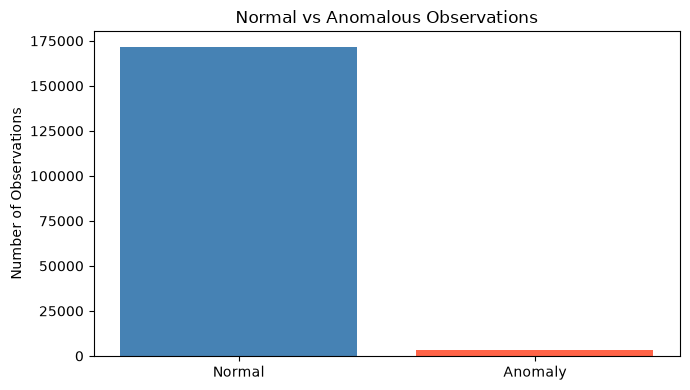

In [6]:

label_counts = df["anomaly_label"].value_counts().sort_index()

label_percentages = (
    df["anomaly_label"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("Observation counts:")
print(label_counts)

print("\nPercentages:")
print(label_percentages.round(2))

plt.figure(figsize=(7, 4))

plt.bar(
    ["Normal", "Anomaly"],
    label_counts.values,
    color=["steelblue", "tomato"]
)

plt.title("Normal vs Anomalous Observations")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()


Anomalous observations by type:
anomaly_type
production_disruption    1671
pressure_loss            1126
sensor_malfunction        707
Name: count, dtype: int64

Percentage of all anomalies:
anomaly_type
production_disruption    47.69
pressure_loss            32.13
sensor_malfunction       20.18
Name: count, dtype: float64


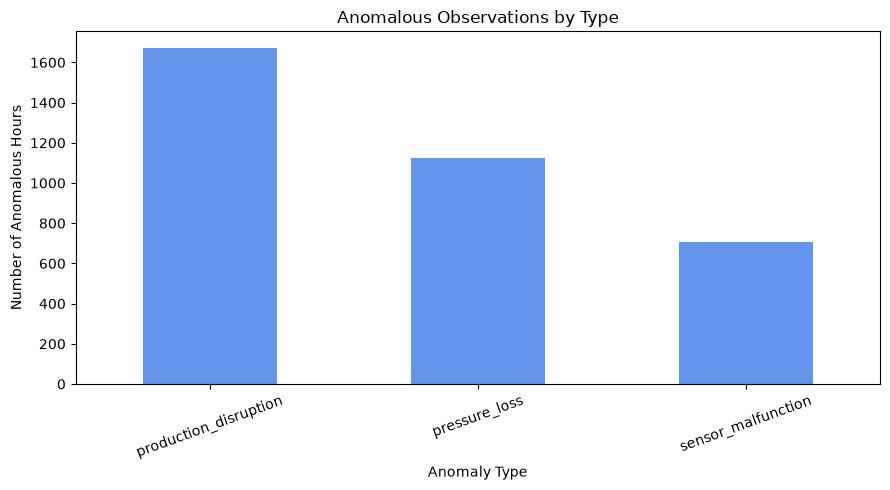

In [7]:

anomaly_counts = (
    df.loc[df["anomaly_label"] == 1, "anomaly_type"]
    .value_counts()
)

print("Anomalous observations by type:")
print(anomaly_counts)

print("\nPercentage of all anomalies:")
print(
    (anomaly_counts / anomaly_counts.sum() * 100)
    .round(2)
)

plt.figure(figsize=(9, 5))

anomaly_counts.plot(
    kind="bar",
    color="cornflowerblue"
)

plt.title("Anomalous Observations by Type")
plt.xlabel("Anomaly Type")
plt.ylabel("Number of Anomalous Hours")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


,total_observations,anomalous_hours,anomaly_percentage
well_id,,,
WELL_001,8760,226,2.58
WELL_002,8760,94,1.07
WELL_003,8760,169,1.93
WELL_004,8760,262,2.99
WELL_005,8760,140,1.60
WELL_006,8760,124,1.42
WELL_007,8760,219,2.50
WELL_008,8760,128,1.46
WELL_009,8760,173,1.97


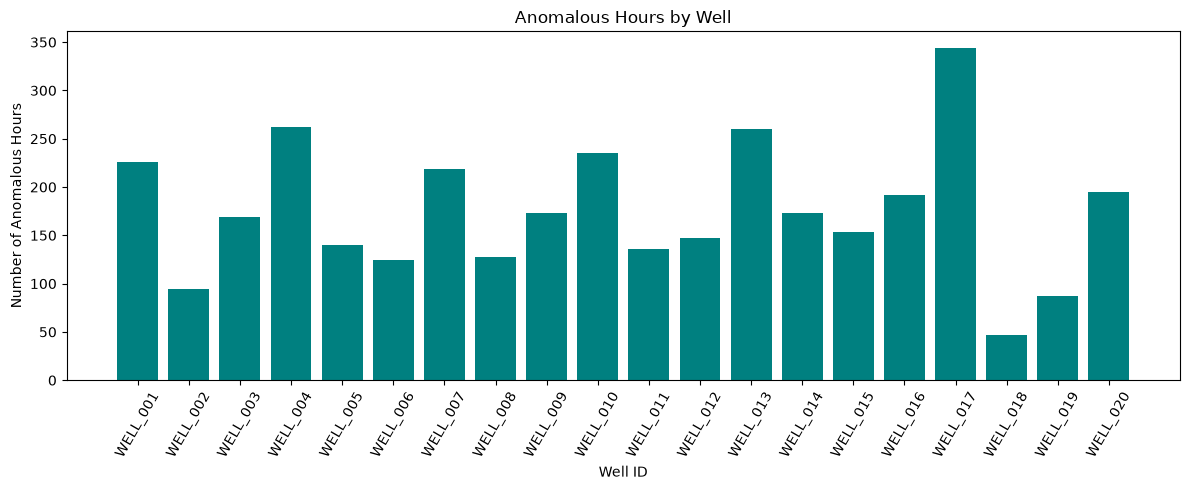

In [8]:

well_summary = (
    df.groupby("well_id")
    .agg(
        total_observations=("anomaly_label", "size"),
        anomalous_hours=("anomaly_label", "sum")
    )
)

well_summary["anomaly_percentage"] = (
    well_summary["anomalous_hours"]
    / well_summary["total_observations"] * 100
)

display(well_summary.round(2))

plt.figure(figsize=(12, 5))

plt.bar(
    well_summary.index,
    well_summary["anomalous_hours"],
    color="teal"
)

plt.title("Anomalous Hours by Well")
plt.xlabel("Well ID")
plt.ylabel("Number of Anomalous Hours")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()


Monthly anomaly counts:
month
2025-01    189
2025-02     87
2025-03     58
2025-04    137
2025-05    188
2025-06    196
2025-07    216
2025-08    109
2025-09    666
2025-10    607
2025-11    490
2025-12    561
Name: anomaly_label, dtype: int64


C:\Users\User\AppData\Local\Temp\ipykernel_13640\4216015296.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["month"] = df["timestamp"].dt.to_period("M").astype(str)


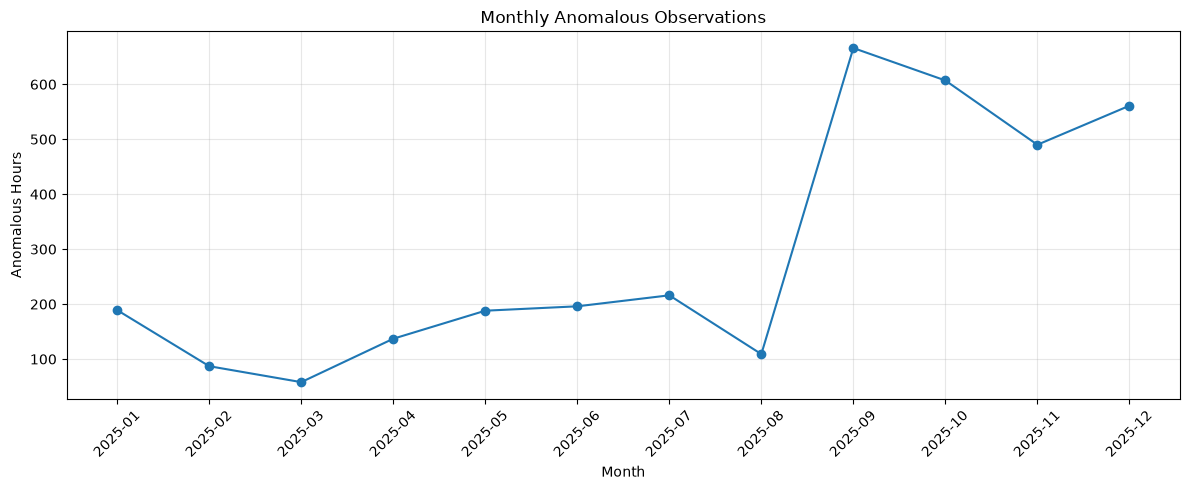

In [9]:

# Create a month column for analysis
df["month"] = df["timestamp"].dt.to_period("M").astype(str)

monthly_anomalies = (
    df.groupby("month")["anomaly_label"]
    .sum()
)

print("Monthly anomaly counts:")
print(monthly_anomalies)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_anomalies.index,
    monthly_anomalies.values,
    marker="o"
)

plt.title("Monthly Anomalous Observations")
plt.xlabel("Month")
plt.ylabel("Anomalous Hours")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:

events_path = (
    project_root
    / "data"
    / "raw"
    / "anomaly_events.csv"
)

events = pd.read_csv(
    events_path,
    parse_dates=["start_time", "end_time"]
)

print("Total anomaly events:", len(events))

display(events.head())

print("\nEvents by injection method:")
print(events["injection_method"].value_counts())

print("\nEvent duration statistics:")
display(
    events.groupby("injection_method")["duration_hours"]
    .describe()
    .round(2)
)


Total anomaly events: 170


,event_id,well_id,start_time,end_time,duration_hours,anomaly_type,injection_method,severity,split
0,EVT_0001,WELL_016,2025-09-18 02:00:00+00:00,2025-09-19 12:00:00+00:00,34,pressure_loss,pressure_loss,0.364649,val
1,EVT_0002,WELL_005,2025-11-05 18:00:00+00:00,2025-11-05 23:00:00+00:00,5,sensor_malfunction,sensor_flatline,NaN,val
2,EVT_0003,WELL_016,2025-12-04 23:00:00+00:00,2025-12-05 18:00:00+00:00,19,sensor_malfunction,sensor_flatline,NaN,test
3,EVT_0004,WELL_017,2025-08-24 20:00:00+00:00,2025-08-25 21:00:00+00:00,25,pressure_loss,pressure_loss,0.242700,train
4,EVT_0005,WELL_013,2025-12-01 21:00:00+00:00,2025-12-01 23:00:00+00:00,2,sensor_malfunction,sensor_spike,0.521707,test



Events by injection method:
injection_method
sensor_flatline          47
pressure_loss            42
sensor_spike             42
production_disruption    39
Name: count, dtype: int64

Event duration statistics:


,count,mean,std,min,25%,50%,75%,max
injection_method,,,,,,,,
pressure_loss,42.0,26.81,12.93,7.0,15.25,26.0,40.00,48.0
production_disruption,39.0,42.85,17.88,7.0,31.00,39.0,57.50,72.0
sensor_flatline,47.0,13.43,5.79,4.0,9.00,13.0,19.00,24.0
sensor_spike,42.0,1.81,0.83,1.0,1.00,2.0,2.75,3.0


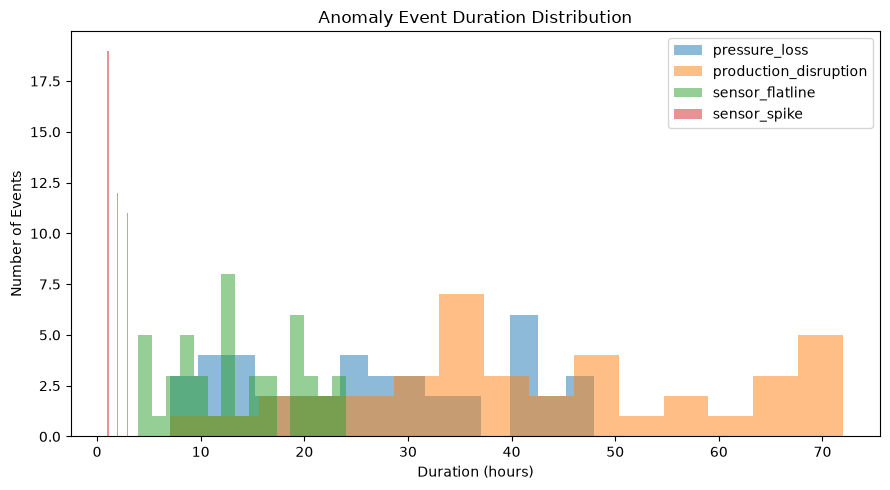

In [11]:

plt.figure(figsize=(9, 5))

for method, group in events.groupby("injection_method"):
    plt.hist(
        group["duration_hours"],
        bins=15,
        alpha=0.5,
        label=method
    )

plt.title("Anomaly Event Duration Distribution")
plt.xlabel("Duration (hours)")
plt.ylabel("Number of Events")
plt.legend()
plt.tight_layout()
plt.show()


In [12]:

# Total anomaly hours must match the event log
assert (
    df["anomaly_label"].sum()
    == events["duration_hours"].sum()
)

# Exactly three main anomaly categories
assert set(
    df.loc[df["anomaly_label"] == 1, "anomaly_type"]
) == {
    "pressure_loss",
    "production_disruption",
    "sensor_malfunction"
}

# Every well must have 8760 observations
assert (
    df.groupby("well_id").size() == 8760
).all()

print("All anomaly distribution checks passed!")


All anomaly distribution checks passed!


In [13]:

features = [
    "oil_rate",
    "gas_rate",
    "water_rate",
    "tubing_pressure",
    "casing_pressure",
    "temperature",
    "choke_size",
]

# Compare feature statistics by anomaly category
summary = (
    df.groupby("anomaly_type")[features]
    .agg(["mean", "std", "min", "max"])
    .round(2)
)

display(summary)


oil_rate                          gas_rate                          water_rate                 \
                          mean     std     min      max     mean     std     min      max       mean     std    min   
anomaly_type                                                                                                          
normal                  800.26  247.01  313.03  1520.98   464.12  157.40  192.84  1054.15     213.56  171.49  32.87   
pressure_loss           779.22  267.29  367.55  1489.90   430.10  146.62  217.81   806.06     200.25  169.82  43.24   
production_disruption   370.16  144.63  140.85   758.46   229.51  108.31   88.55   529.54      89.81   83.97  16.41   
sensor_malfunction      664.88  186.85  332.71  1145.39   424.91  148.96  217.50   857.83     153.78  131.38  35.43   

                              tubing_pressure                           casing_pressure                            \
                          max            mean     std      min      max            mean     std      min      max   
anomaly_type                                                                                                        
normal                 728.85         1750.29  300.35  1256.08  2327.53         2075.92  310.55  1503.43  2646.82   
pressure_loss          713.95         1239.78  259.94   795.15  1838.24         2083.36  297.34  1530.02  2607.32   
production_disruption  362.59         1716.30  303.63  1294.62  2215.35         2067.36  306.98  1530.85  2592.20   
sensor_malfunction     523.64         1794.76  447.37  1280.64  3699.13         2023.27  332.39  1513.13  2639.62   

                      temperature                        choke_size                       
                             mean    std     min     max       mean    std    min    max  
anomaly_type                                                                              
normal                     151.69  13.77  125.99  181.45      69.66  14.10  41.14  88.46  
pressure_loss              152.24  13.28  128.45  180.18      70.40  14.97  41.14  88.46  
production_disruption      150.37  13.17  126.92  177.52      70.73  15.69  41.14  88.46  
sensor_malfunction         148.54  12.15  128.03  177.60      66.46  16.03  41.14  88.46

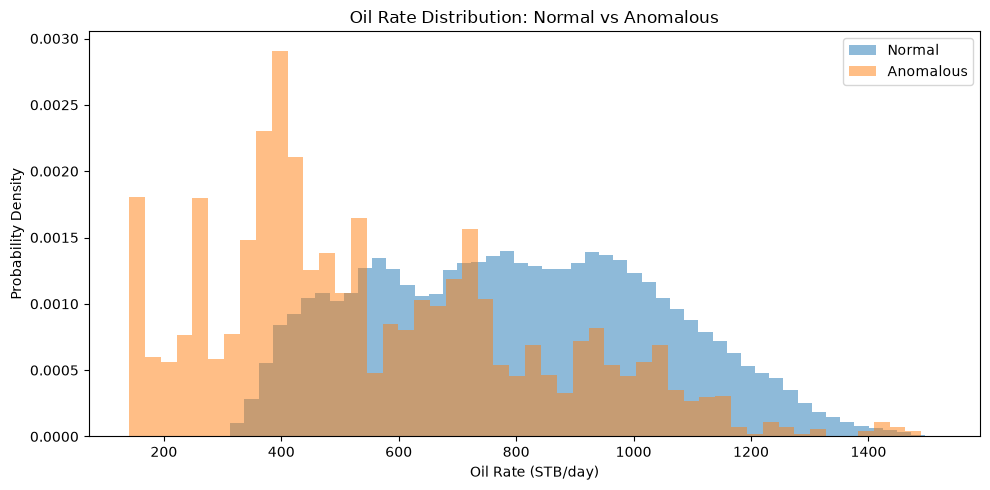

In [14]:

normal_oil = df.loc[
    df["anomaly_label"] == 0,
    "oil_rate"
]

anomalous_oil = df.loc[
    df["anomaly_label"] == 1,
    "oil_rate"
]

plt.figure(figsize=(10, 5))

plt.hist(
    normal_oil,
    bins=50,
    density=True,
    alpha=0.5,
    label="Normal"
)

plt.hist(
    anomalous_oil,
    bins=50,
    density=True,
    alpha=0.5,
    label="Anomalous"
)

plt.title("Oil Rate Distribution: Normal vs Anomalous")
plt.xlabel("Oil Rate (STB/day)")
plt.ylabel("Probability Density")
plt.legend()
plt.tight_layout()
plt.show()


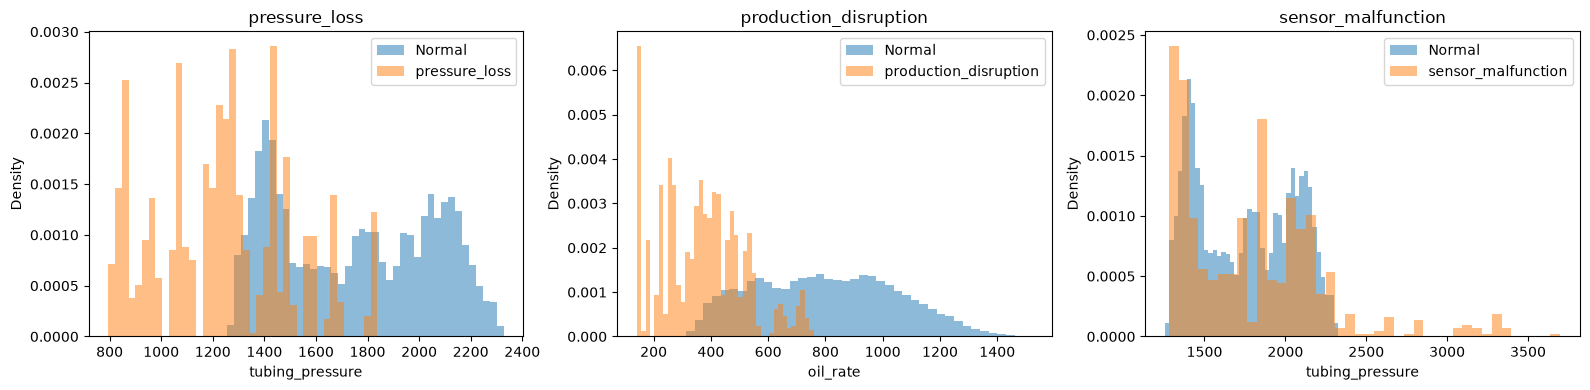

In [15]:

comparisons = [
    ("pressure_loss", "tubing_pressure"),
    ("production_disruption", "oil_rate"),
    ("sensor_malfunction", "tubing_pressure"),
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4)
)

for ax, (anomaly_type, feature) in zip(
    axes, comparisons
):
    normal_values = df.loc[
        df["anomaly_type"] == "normal",
        feature
    ]

    anomaly_values = df.loc[
        df["anomaly_type"] == anomaly_type,
        feature
    ]

    ax.hist(
        normal_values,
        bins=40,
        density=True,
        alpha=0.5,
        label="Normal"
    )

    ax.hist(
        anomaly_values,
        bins=40,
        density=True,
        alpha=0.5,
        label=anomaly_type
    )

    ax.set_title(anomaly_type)
    ax.set_xlabel(feature)
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()


In [16]:

df_normal = pd.read_csv(
    project_root / "data/raw/wells_normal.csv",
    parse_dates=["timestamp"]
)

# Join original values with anomalous observations
comparison_df = df.merge(
    df_normal[
        [
            "well_id",
            "timestamp",
            "oil_rate",
            "tubing_pressure",
            "temperature",
        ]
    ],
    on=["well_id", "timestamp"],
    suffixes=("", "_baseline"),
    validate="one_to_one"
)

print("Comparison dataset:", comparison_df.shape)


Comparison dataset: (175200, 15)


In [17]:

comparison_df["oil_change_pct"] = (
    (
        comparison_df["oil_rate"]
        - comparison_df["oil_rate_baseline"]
    )
    / comparison_df["oil_rate_baseline"]
    * 100
)

comparison_df["pressure_change_pct"] = (
    (
        comparison_df["tubing_pressure"]
        - comparison_df["tubing_pressure_baseline"]
    )
    / comparison_df["tubing_pressure_baseline"]
    * 100
)

display(
    comparison_df.groupby("anomaly_type")[
        ["oil_change_pct", "pressure_change_pct"]
    ].agg(["mean", "min", "max"]).round(2)
)


oil_change_pct               pressure_change_pct              
                                mean    min    max                mean    min    max
anomaly_type                                                                        
normal                          0.00   0.00   0.00                0.00   0.00   0.00
pressure_loss                   0.00   0.00   0.00              -29.14 -38.96 -15.53
production_disruption         -50.05 -68.12 -30.99                0.00   0.00   0.00
sensor_malfunction              0.00   0.00   0.00                6.06  -2.33  79.52

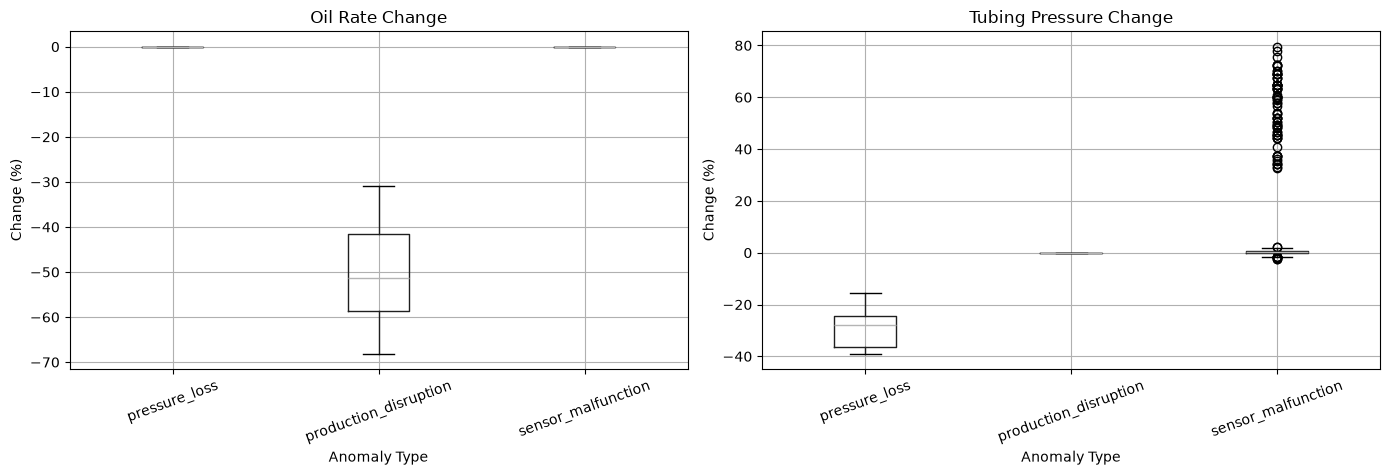

In [18]:

anomaly_only = comparison_df[
    comparison_df["anomaly_label"] == 1
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

anomaly_only.boxplot(
    column="oil_change_pct",
    by="anomaly_type",
    ax=axes[0]
)

anomaly_only.boxplot(
    column="pressure_change_pct",
    by="anomaly_type",
    ax=axes[1]
)

axes[0].set_title("Oil Rate Change")
axes[0].set_ylabel("Change (%)")

axes[1].set_title("Tubing Pressure Change")
axes[1].set_ylabel("Change (%)")

for ax in axes:
    ax.tick_params(axis="x", rotation=20)
    ax.set_xlabel("Anomaly Type")

plt.suptitle("")
plt.tight_layout()
plt.show()


In [19]:

print("Dataset shape:", df.shape)
print("Total events:", len(events))

print("\nAvailable anomaly methods:")
print(events["injection_method"].value_counts())

display(events.head())


Dataset shape: (175200, 12)
Total events: 170

Available anomaly methods:
injection_method
sensor_flatline          47
pressure_loss            42
sensor_spike             42
production_disruption    39
Name: count, dtype: int64


,event_id,well_id,start_time,end_time,duration_hours,anomaly_type,injection_method,severity,split
0,EVT_0001,WELL_016,2025-09-18 02:00:00+00:00,2025-09-19 12:00:00+00:00,34,pressure_loss,pressure_loss,0.364649,val
1,EVT_0002,WELL_005,2025-11-05 18:00:00+00:00,2025-11-05 23:00:00+00:00,5,sensor_malfunction,sensor_flatline,NaN,val
2,EVT_0003,WELL_016,2025-12-04 23:00:00+00:00,2025-12-05 18:00:00+00:00,19,sensor_malfunction,sensor_flatline,NaN,test
3,EVT_0004,WELL_017,2025-08-24 20:00:00+00:00,2025-08-25 21:00:00+00:00,25,pressure_loss,pressure_loss,0.242700,train
4,EVT_0005,WELL_013,2025-12-01 21:00:00+00:00,2025-12-01 23:00:00+00:00,2,sensor_malfunction,sensor_spike,0.521707,test


In [20]:

# Select the first pressure-loss event
event = events[
    events["injection_method"] == "pressure_loss"
].iloc[0]

well_id = event["well_id"]
start_time = event["start_time"]
end_time = event["end_time"]

print("Well:", well_id)
print("Event:", event["event_id"])
print("Start:", start_time)
print("End:", end_time)
print("Duration:", event["duration_hours"], "hours")


Well: WELL_016
Event: EVT_0001
Start: 2025-09-18 02:00:00+00:00
End: 2025-09-19 12:00:00+00:00
Duration: 34 hours


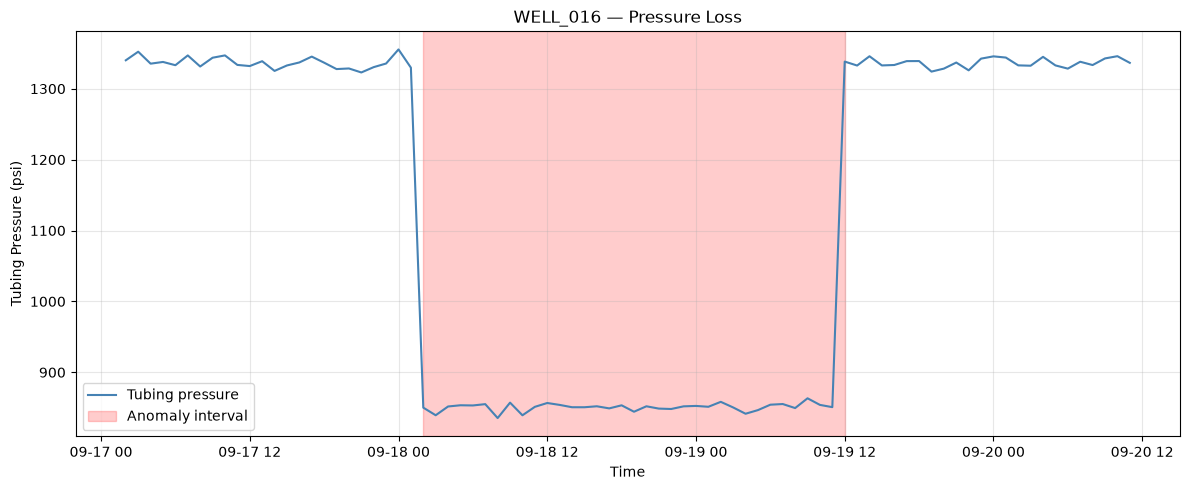

In [21]:

# Show 24 hours before and after the event
plot_start = start_time - pd.Timedelta(hours=24)
plot_end = end_time + pd.Timedelta(hours=24)

mask = (
    (df["well_id"] == well_id)
    & (df["timestamp"] >= plot_start)
    & (df["timestamp"] < plot_end)
)

well_data = df.loc[mask].sort_values("timestamp")

plt.figure(figsize=(12, 5))

plt.plot(
    well_data["timestamp"],
    well_data["tubing_pressure"],
    label="Tubing pressure",
    color="steelblue"
)

# Highlight the anomaly interval
plt.axvspan(
    start_time,
    end_time,
    color="red",
    alpha=0.2,
    label="Anomaly interval"
)

plt.title(f"{well_id} — Pressure Loss")
plt.xlabel("Time")
plt.ylabel("Tubing Pressure (psi)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


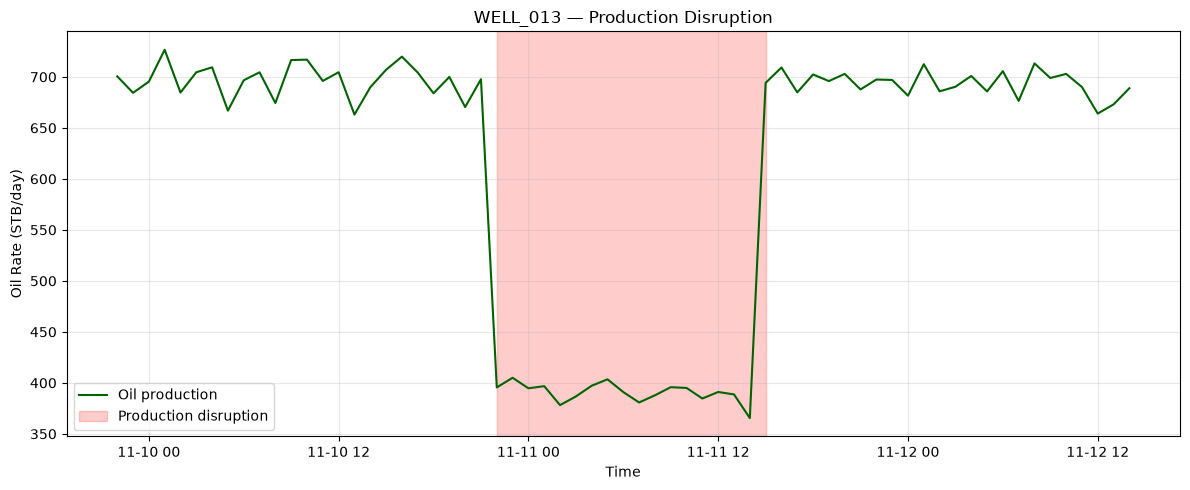

In [22]:

event = events[
    events["injection_method"] == "production_disruption"
].iloc[0]

well_id = event["well_id"]
start_time = event["start_time"]
end_time = event["end_time"]

plot_start = start_time - pd.Timedelta(hours=24)
plot_end = end_time + pd.Timedelta(hours=24)

mask = (
    (df["well_id"] == well_id)
    & (df["timestamp"] >= plot_start)
    & (df["timestamp"] < plot_end)
)

well_data = df.loc[mask].sort_values("timestamp")

plt.figure(figsize=(12, 5))

plt.plot(
    well_data["timestamp"],
    well_data["oil_rate"],
    label="Oil production",
    color="darkgreen"
)

plt.axvspan(
    start_time,
    end_time,
    color="red",
    alpha=0.2,
    label="Production disruption"
)

plt.title(f"{well_id} — Production Disruption")
plt.xlabel("Time")
plt.ylabel("Oil Rate (STB/day)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


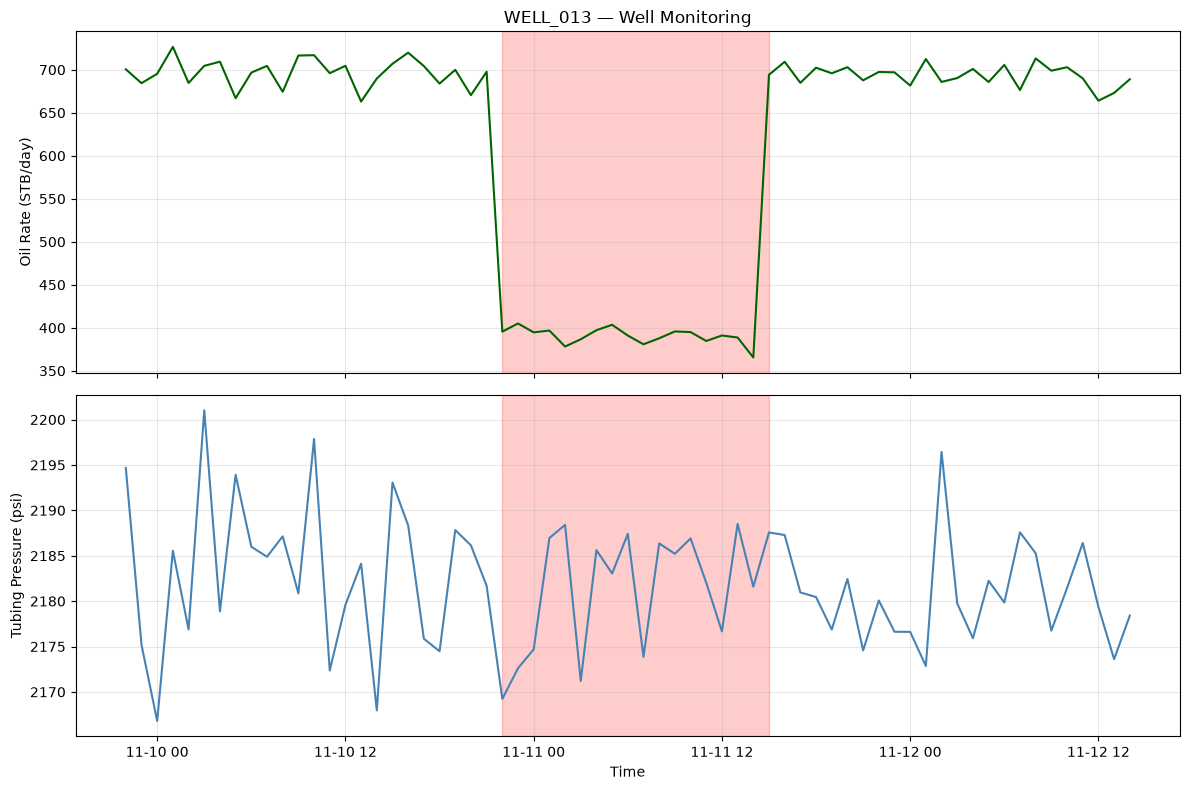

In [23]:

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True
)

# Oil production
axes[0].plot(
    well_data["timestamp"],
    well_data["oil_rate"],
    color="darkgreen"
)

axes[0].set_ylabel("Oil Rate (STB/day)")
axes[0].set_title(f"{well_id} — Well Monitoring")

# Tubing pressure
axes[1].plot(
    well_data["timestamp"],
    well_data["tubing_pressure"],
    color="steelblue"
)

axes[1].set_ylabel("Tubing Pressure (psi)")
axes[1].set_xlabel("Time")

# Highlight event in both charts
for ax in axes:
    ax.axvspan(
        start_time,
        end_time,
        color="red",
        alpha=0.2
    )
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [24]:

def plot_anomaly_event(
    df,
    events,
    event_id,
    feature="tubing_pressure",
    context_hours=24,
):
    """Plot any anomaly event with surrounding data."""

    # Find the requested event
    matches = events[
        events["event_id"] == event_id
    ]

    if matches.empty:
        raise ValueError(f"Event {event_id} not found.")

    event = matches.iloc[0]

    well_id = event["well_id"]
    start_time = event["start_time"]
    end_time = event["end_time"]

    # Select surrounding observations
    plot_start = start_time - pd.Timedelta(
        hours=context_hours
    )
    plot_end = end_time + pd.Timedelta(
        hours=context_hours
    )

    mask = (
        (df["well_id"] == well_id)
        & (df["timestamp"] >= plot_start)
        & (df["timestamp"] < plot_end)
    )

    well_data = df.loc[mask].sort_values(
        "timestamp"
    )

    if feature not in well_data.columns:
        raise ValueError(f"Unknown feature: {feature}")

    fig, ax = plt.subplots(figsize=(12, 5))

    ax.plot(
        well_data["timestamp"],
        well_data[feature],
        label=feature
    )

    ax.axvspan(
        start_time,
        end_time,
        color="red",
        alpha=0.2,
        label="Anomaly interval"
    )

    ax.set_title(
        f"{well_id} — {event['injection_method']} "
        f"({event_id})"
    )

    ax.set_xlabel("Time")
    ax.set_ylabel(feature)
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


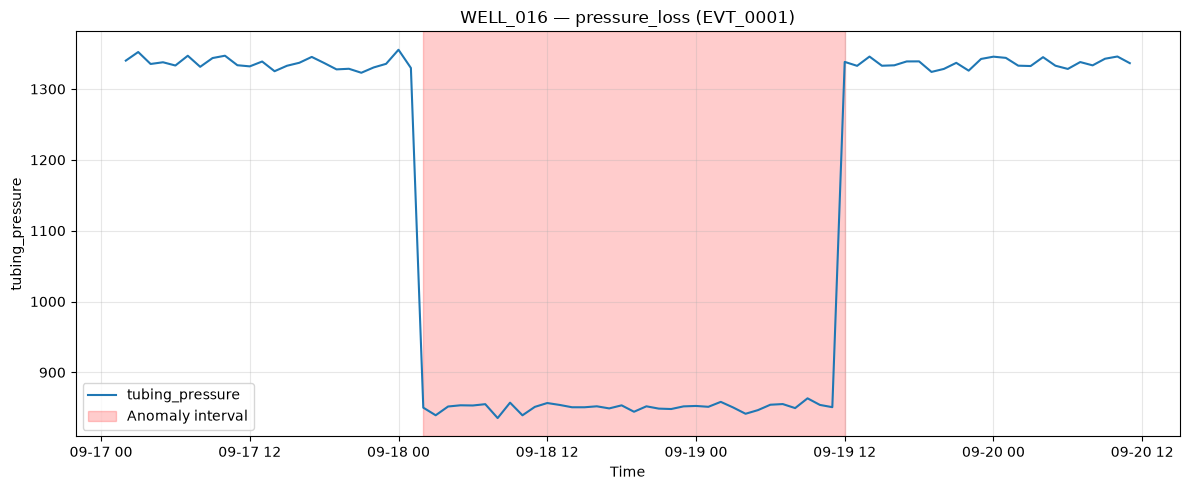

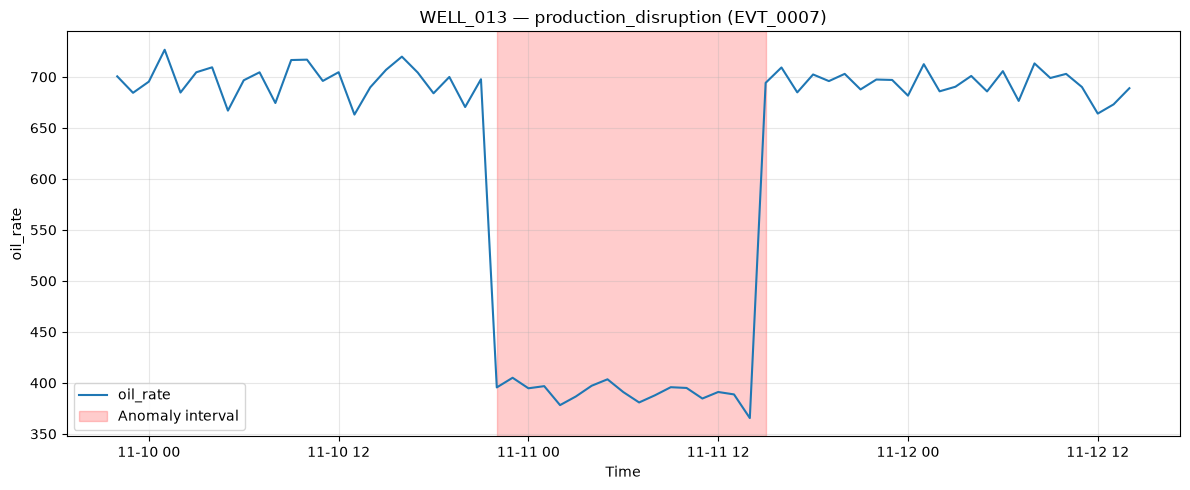

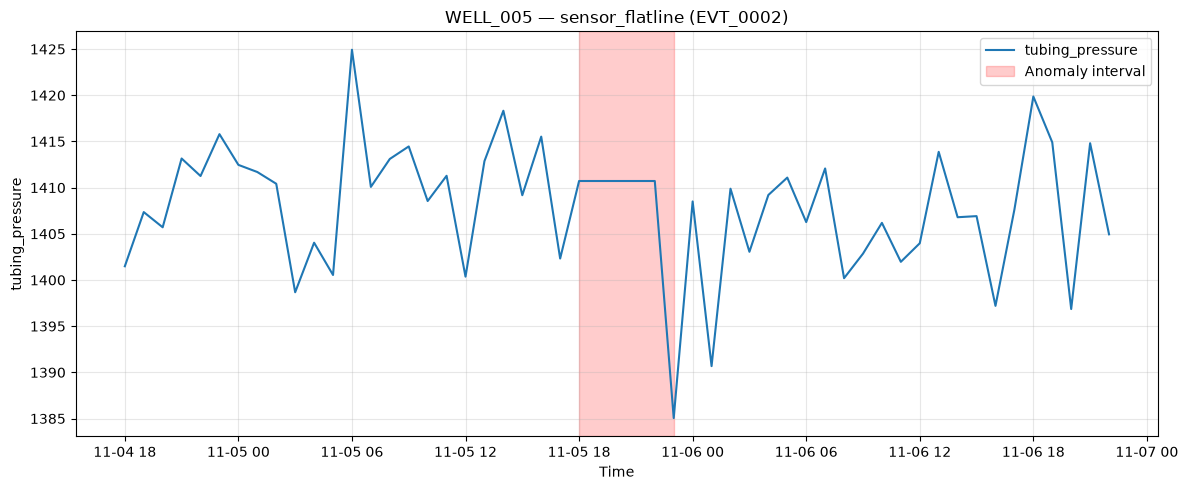

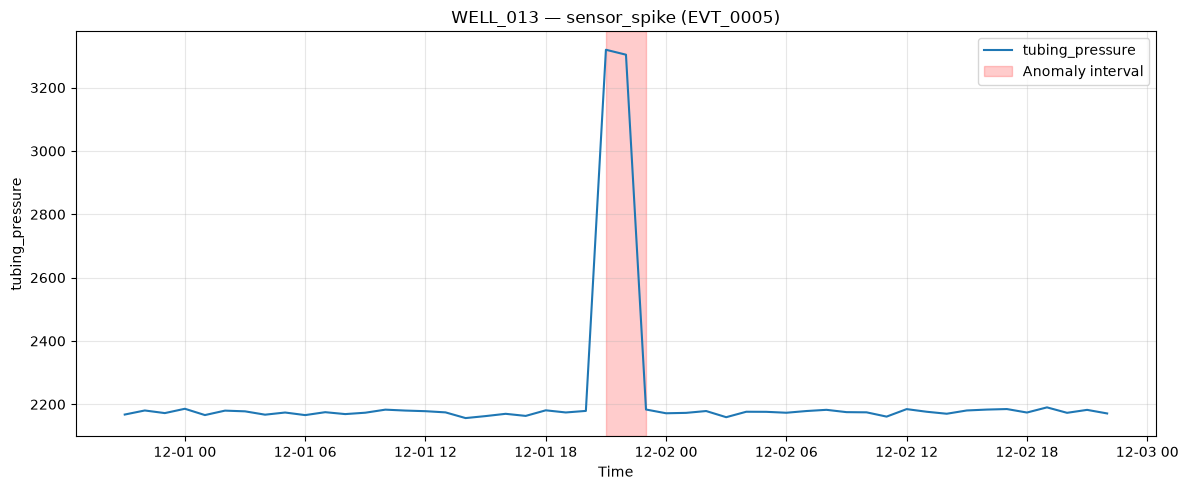

In [25]:

# Select an event of each type
for method, feature in [
    ("pressure_loss", "tubing_pressure"),
    ("production_disruption", "oil_rate"),
    ("sensor_flatline", "tubing_pressure"),
    ("sensor_spike", "tubing_pressure"),
]:
    event_id = events.loc[
        events["injection_method"] == method,
        "event_id"
    ].iloc[0]

    plot_anomaly_event(
        df,
        events,
        event_id=event_id,
        feature=feature,
    )


In [26]:

features = [
    "oil_rate",
    "gas_rate",
    "water_rate",
    "tubing_pressure",
    "casing_pressure",
    "temperature",
    "choke_size",
]

correlation_matrix = df[features].corr()

display(correlation_matrix.round(2))


,oil_rate,gas_rate,water_rate,tubing_pressure,casing_pressure,temperature,choke_size
oil_rate,1.00,0.38,0.61,-0.17,-0.19,0.43,0.33
gas_rate,0.38,1.00,0.30,0.16,0.16,0.17,0.25
water_rate,0.61,0.30,1.00,-0.21,-0.23,0.54,0.12
tubing_pressure,-0.17,0.16,-0.21,1.00,0.97,0.07,0.18
casing_pressure,-0.19,0.16,-0.23,0.97,1.00,0.02,0.16
temperature,0.43,0.17,0.54,0.07,0.02,1.00,0.37
choke_size,0.33,0.25,0.12,0.18,0.16,0.37,1.00


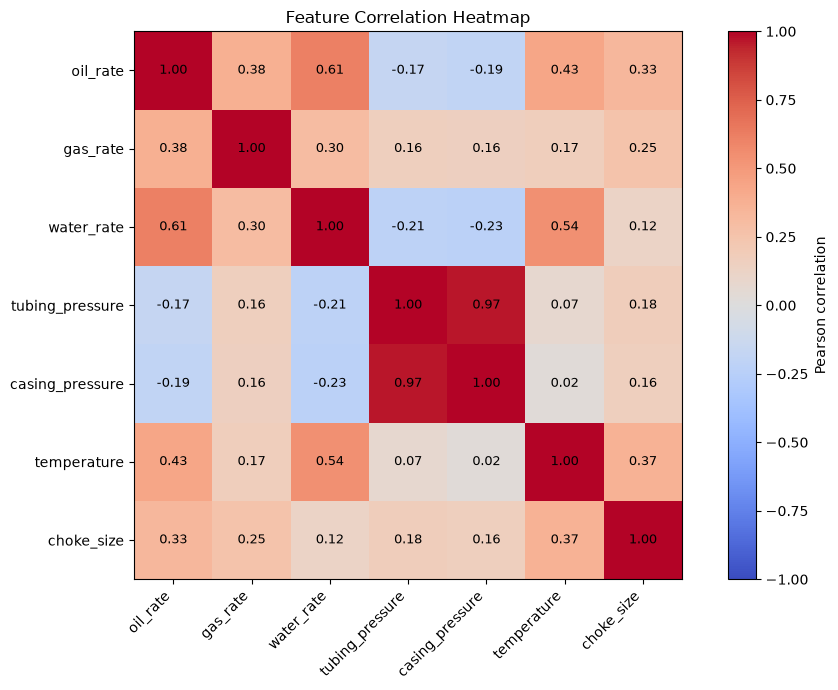

In [27]:

fig, ax = plt.subplots(figsize=(10, 7))

im = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(features)))
ax.set_yticks(range(len(features)))

ax.set_xticklabels(features, rotation=45, ha="right")
ax.set_yticklabels(features)

# Display correlation values
for i in range(len(features)):
    for j in range(len(features)):
        ax.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

plt.colorbar(im, ax=ax, label="Pearson correlation")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


In [28]:

# Field-wide correlation
field_corr = df[
    ["oil_rate", "tubing_pressure"]
].corr().iloc[0, 1]

# Correlation within WELL_001
well_001 = df[
    df["well_id"] == "WELL_001"
]

well_corr = well_001[
    ["oil_rate", "tubing_pressure"]
].corr().iloc[0, 1]

print(f"Field-wide correlation: {field_corr:.3f}")
print(f"WELL_001 correlation: {well_corr:.3f}")


Field-wide correlation: -0.169
WELL_001 correlation: 0.689


In [29]:

# Negative measurement checks
nonnegative_features = [
    "oil_rate",
    "gas_rate",
    "water_rate",
    "tubing_pressure",
    "casing_pressure",
]

print("Negative values:")
print((df[nonnegative_features] < 0).sum())

# Choke size limits
invalid_choke = (
    (df["choke_size"] < 0)
    | (df["choke_size"] > 100)
)

print("\nInvalid choke values:", invalid_choke.sum())

# Duplicate timestamps per well
duplicates = df.duplicated(
    ["well_id", "timestamp"]
).sum()

print("Duplicate well-timestamp records:", duplicates)

# Missing values
print("\nMissing values:")
print(df.isna().sum())


Negative values:
oil_rate           0
gas_rate           0
water_rate         0
tubing_pressure    0
casing_pressure    0
dtype: int64

Invalid choke values: 0
Duplicate well-timestamp records: 0

Missing values:
well_id            0
timestamp          0
oil_rate           0
gas_rate           0
water_rate         0
tubing_pressure    0
casing_pressure    0
temperature        0
choke_size         0
anomaly_label      0
anomaly_type       0
month              0
dtype: int64


In [30]:

df_sorted = df.sort_values(
    ["well_id", "timestamp"]
).copy()

df_sorted["time_difference"] = (
    df_sorted.groupby("well_id")["timestamp"]
    .diff()
)

# Exclude the first observation of each well
time_diffs = df_sorted["time_difference"].dropna()

unexpected_gaps = (
    time_diffs != pd.Timedelta(hours=1)
).sum()

print("Unexpected timestamp gaps:", unexpected_gaps)

assert unexpected_gaps == 0

print("Hourly timestamp continuity verified!")


Unexpected timestamp gaps: 0
Hourly timestamp continuity verified!


In [32]:

model_features = [
    "oil_rate",
    "gas_rate",
    "water_rate",
    "tubing_pressure",
    "casing_pressure",
    "temperature",
    "choke_size",
]

target_column = "anomaly_label"

X = df[model_features]
y = df[target_column]

print("Feature matrix:", X.shape)
print("Target vector:", y.shape)

assert "anomaly_label" not in X.columns
assert "anomaly_type" not in X.columns

print("No target columns included in model features!")


Feature matrix: (175200, 7)
Target vector: (175200,)
No target columns included in model features!
